<a href="https://colab.research.google.com/github/sneha121083-dotcom/House_Prediction_Model/blob/main/House_Price_Prediction_Model.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
from google.colab import files

uploaded = files.upload()

Saving train.csv to train.csv


In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

print("All libraries imported successfully!")

All libraries imported successfully!


In [3]:
df = pd.read_csv('train.csv')

print("Dataset loaded successfully!")
print("Dataset Shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset Shape: (1460, 81)


,Id,MSSubClass,MSZoning,LotFrontage,LotArea,Street,Alley,LotShape,LandContour,Utilities,...,PoolArea,PoolQC,Fence,MiscFeature,MiscVal,MoSold,YrSold,SaleType,SaleCondition,SalePrice
0,1,60,RL,65.0,8450,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2008,WD,Normal,208500
1,2,20,RL,80.0,9600,Pave,NaN,Reg,Lvl,AllPub,...,0,NaN,NaN,NaN,0,5,2007,WD,Normal,181500
2,3,60,RL,68.0,11250,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,9,2008,WD,Normal,223500
3,4,70,RL,60.0,9550,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,2,2006,WD,Abnorml,140000
4,5,60,RL,84.0,14260,Pave,NaN,IR1,Lvl,AllPub,...,0,NaN,NaN,NaN,0,12,2008,WD,Normal,250000


In [4]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1460 entries, 0 to 1459
Data columns (total 81 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Id             1460 non-null   int64  
 1   MSSubClass     1460 non-null   int64  
 2   MSZoning       1460 non-null   object 
 3   LotFrontage    1201 non-null   float64
 4   LotArea        1460 non-null   int64  
 5   Street         1460 non-null   object 
 6   Alley          91 non-null     object 
 7   LotShape       1460 non-null   object 
 8   LandContour    1460 non-null   object 
 9   Utilities      1460 non-null   object 
 10  LotConfig      1460 non-null   object 
 11  LandSlope      1460 non-null   object 
 12  Neighborhood   1460 non-null   object 
 13  Condition1     1460 non-null   object 
 14  Condition2     1460 non-null   object 
 15  BldgType       1460 non-null   object 
 16  HouseStyle     1460 non-null   object 
 17  OverallQual    1460 non-null   int64  
 18  OverallC

In [5]:
df.describe()

,Id,MSSubClass,LotFrontage,LotArea,OverallQual,OverallCond,YearBuilt,YearRemodAdd,MasVnrArea,BsmtFinSF1,...,WoodDeckSF,OpenPorchSF,EnclosedPorch,3SsnPorch,ScreenPorch,PoolArea,MiscVal,MoSold,YrSold,SalePrice
count,1460.000000,1460.000000,1201.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1452.000000,1460.000000,...,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000,1460.000000
mean,730.500000,56.897260,70.049958,10516.828082,6.099315,5.575342,1971.267808,1984.865753,103.685262,443.639726,...,94.244521,46.660274,21.954110,3.409589,15.060959,2.758904,43.489041,6.321918,2007.815753,180921.195890
std,421.610009,42.300571,24.284752,9981.264932,1.382997,1.112799,30.202904,20.645407,181.066207,456.098091,...,125.338794,66.256028,61.119149,29.317331,55.757415,40.177307,496.123024,2.703626,1.328095,79442.502883
min,1.000000,20.000000,21.000000,1300.000000,1.000000,1.000000,1872.000000,1950.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000,2006.000000,34900.000000
25%,365.750000,20.000000,59.000000,7553.500000,5.000000,5.000000,1954.000000,1967.000000,0.000000,0.000000,...,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,5.000000,2007.000000,129975.000000
50%,730.500000,50.000000,69.000000,9478.500000,6.000000,5.000000,1973.000000,1994.000000,0.000000,383.500000,...,0.000000,25.000000,0.000000,0.000000,0.000000,0.000000,0.000000,6.000000,2008.000000,163000.000000
75%,1095.250000,70.000000,80.000000,11601.500000,7.000000,6.000000,2000.000000,2004.000000,166.000000,712.250000,...,168.000000,68.000000,0.000000,0.000000,0.000000,0.000000,0.000000,8.000000,2009.000000,214000.000000
max,1460.000000,190.000000,313.000000,215245.000000,10.000000,9.000000,2010.000000,2010.000000,1600.000000,5644.000000,...,857.000000,547.000000,552.000000,508.000000,480.000000,738.000000,15500.000000,12.000000,2010.000000,755000.000000


In [6]:
print(df.isnull().sum().sort_values(ascending=False).head(20))

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageQual        81
GarageFinish      81
GarageType        81
GarageYrBlt       81
GarageCond        81
BsmtFinType2      38
BsmtExposure      38
BsmtCond          37
BsmtQual          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
Condition2         0
dtype: int64


In [7]:
print(df['SalePrice'].describe())

count      1460.000000
mean     180921.195890
std       79442.502883
min       34900.000000
25%      129975.000000
50%      163000.000000
75%      214000.000000
max      755000.000000
Name: SalePrice, dtype: float64


In [8]:
missing_values = df.isnull().sum()

missing_values = missing_values[missing_values > 0].sort_values(ascending=False)

print(missing_values)

PoolQC          1453
MiscFeature     1406
Alley           1369
Fence           1179
MasVnrType       872
FireplaceQu      690
LotFrontage      259
GarageType        81
GarageYrBlt       81
GarageFinish      81
GarageQual        81
GarageCond        81
BsmtExposure      38
BsmtFinType2      38
BsmtQual          37
BsmtCond          37
BsmtFinType1      37
MasVnrArea         8
Electrical         1
dtype: int64


In [9]:
numerical_cols = df.select_dtypes(include=['int64', 'float64']).columns

categorical_cols = df.select_dtypes(include=['object']).columns

print("Numerical columns:", len(numerical_cols))
print("Categorical columns:", len(categorical_cols))

Numerical columns: 38
Categorical columns: 43


In [10]:
for col in numerical_cols:
    df[col] = df[col].fillna(df[col].median())

for col in categorical_cols:
    df[col] = df[col].fillna(df[col].mode()[0])

In [11]:
df = pd.get_dummies(df, drop_first=True)

print("New dataset shape:", df.shape)

New dataset shape: (1460, 246)


In [12]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


In [13]:
X = df[['OverallQual', 'GrLivArea',
        'BedroomAbvGr', 'FullBath', 'GarageCars']]

y = df['SalePrice']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1460, 5)
Target shape: (1460,)


In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (1168, 5)
Testing data: (292, 5)


In [15]:
# Create the Linear Regression model
model = LinearRegression()

# Train the model
model.fit(X_train, y_train)

print("Linear Regression Model trained successfully!")

Linear Regression Model trained successfully!


In [16]:
# Predict house prices
y_pred = model.predict(X_test)

print("Predicted House Prices:")
print(y_pred[:10])

Predicted House Prices:
[133874.28011031 294805.72807698 136724.28397356 190511.03542467
 293579.85578181  56158.84849752 230063.54386964 178770.89047018
  56158.84849752 127107.10947365]


In [17]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0        154500    133874.280110
1        325000    294805.728077
2        115000    136724.283974
3        159000    190511.035425
4        315500    293579.855782
5         75500     56158.848498
6        311500    230063.543870
7        146000    178770.890470
8         84500     56158.848498
9        135500    127107.109474


In [18]:
comparison = pd.DataFrame({
    'Actual Price': y_test.values,
    'Predicted Price': y_pred
})

print(comparison.head(10))

   Actual Price  Predicted Price
0        154500    133874.280110
1        325000    294805.728077
2        115000    136724.283974
3        159000    190511.035425
4        315500    293579.855782
5         75500     56158.848498
6        311500    230063.543870
7        146000    178770.890470
8         84500     56158.848498
9        135500    127107.109474


In [19]:
# Calculate evaluation metrics
r2 = r2_score(y_test, y_pred)

mae = mean_absolute_error(y_test, y_pred)

mse = mean_squared_error(y_test, y_pred)

print("Model Evaluation Results")
print("------------------------")
print("R2 Score:", r2)
print("MAE:", mae)
print("MSE:", mse)

Model Evaluation Results
------------------------
R2 Score: 0.7718563750322082
MAE: 27814.53793870795
MSE: 1749936025.5931246


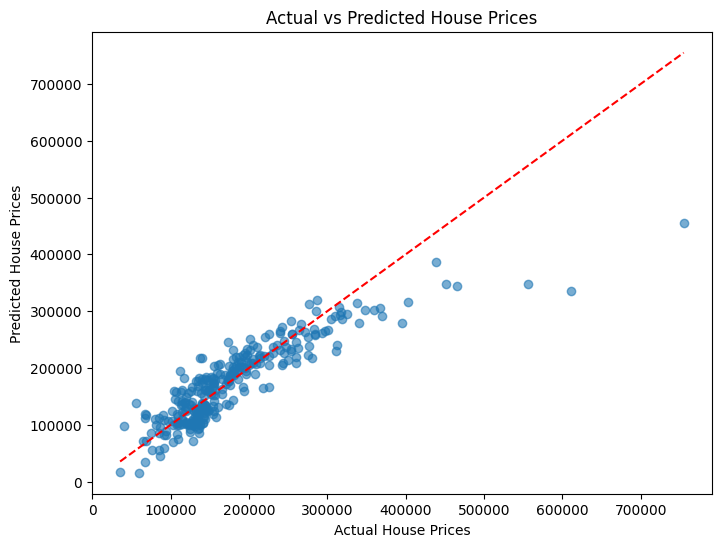

In [20]:
plt.figure(figsize=(8, 6))

plt.scatter(y_test, y_pred, alpha=0.6)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Actual vs Predicted House Prices")

# Perfect prediction reference line
plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    'r--'
)

plt.show()

In [21]:
new_house = pd.DataFrame({
    'OverallQual': [7],
    'GrLivArea': [2000],
    'BedroomAbvGr': [3],
    'FullBath': [2],
    'GarageCars': [2]
})

predicted_price = model.predict(new_house)

print("Predicted House Price: $", round(predicted_price[0], 2))

Predicted House Price: $ 234587.03


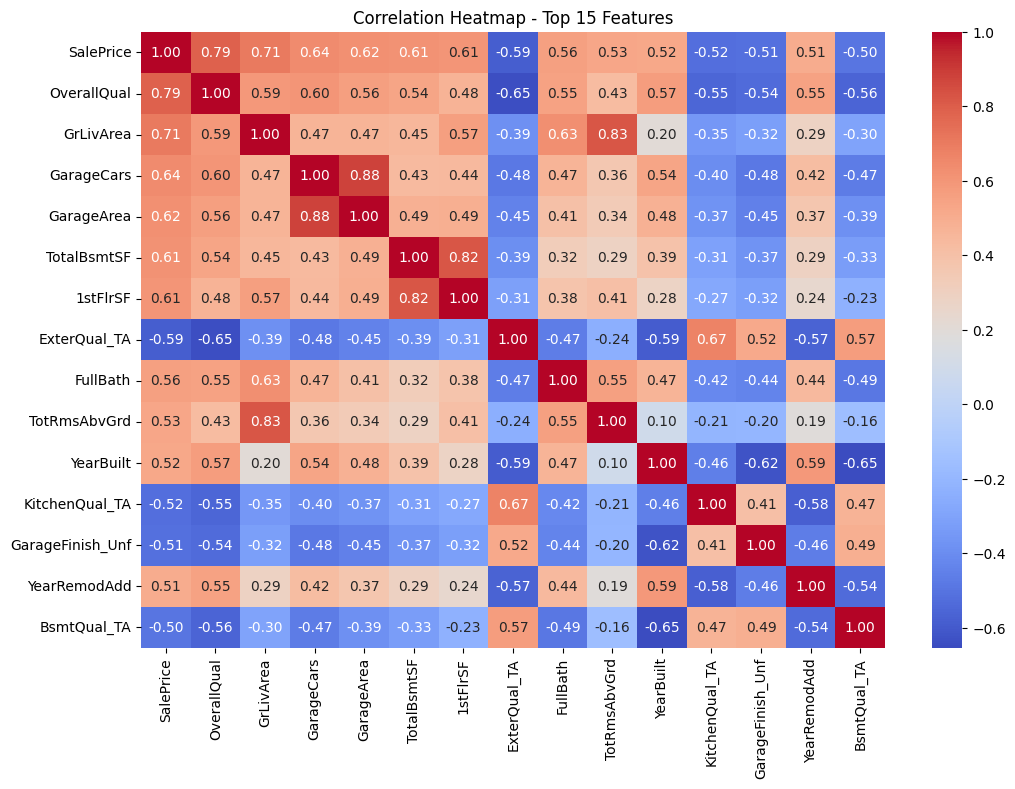

In [22]:
plt.figure(figsize=(12, 8))

correlation = df.corr(numeric_only=True)

top_features = correlation['SalePrice'].abs().sort_values(
    ascending=False
).head(15).index

sns.heatmap(
    df[top_features].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title("Correlation Heatmap - Top 15 Features")
plt.show()

In [23]:
selected_features = [
    'OverallQual',
    'GrLivArea',
    'GarageCars',
    'TotalBsmtSF',
    'FullBath',
    'YearBuilt',
    'YearRemodAdd'
]

In [24]:
# Select improved features
X2 = df[selected_features]
y2 = df['SalePrice']

# Split dataset
X2_train, X2_test, y2_train, y2_test = train_test_split(
    X2, y2, test_size=0.2, random_state=42
)

# Create Linear Regression model
model2 = LinearRegression()

# Train model
model2.fit(X2_train, y2_train)

print("Improved Linear Regression Model trained successfully!")

Improved Linear Regression Model trained successfully!


In [25]:
# Predictions
y2_pred = model2.predict(X2_test)

# Evaluation
r2_2 = r2_score(y2_test, y2_pred)
mae_2 = mean_absolute_error(y2_test, y2_pred)
mse_2 = mean_squared_error(y2_test, y2_pred)

print("MODEL 2 - EVALUATION RESULTS")
print("----------------------------")
print("R2 Score:", r2_2)
print("MAE:", mae_2)
print("MSE:", mse_2)

MODEL 2 - EVALUATION RESULTS
----------------------------
R2 Score: 0.7954057136183966
MAE: 25155.936993316587
MSE: 1569304916.6735604


In [26]:
comparison_results = pd.DataFrame({
    'Metric': ['R2 Score', 'MAE', 'MSE'],
    'Model 1 (5 Features)': [r2, mae, mse],
    'Model 2 (7 Features)': [r2_2, mae_2, mse_2]
})

print(comparison_results)

     Metric  Model 1 (5 Features)  Model 2 (7 Features)
0  R2 Score          7.718564e-01          7.954057e-01
1       MAE          2.781454e+04          2.515594e+04
2       MSE          1.749936e+09          1.569305e+09


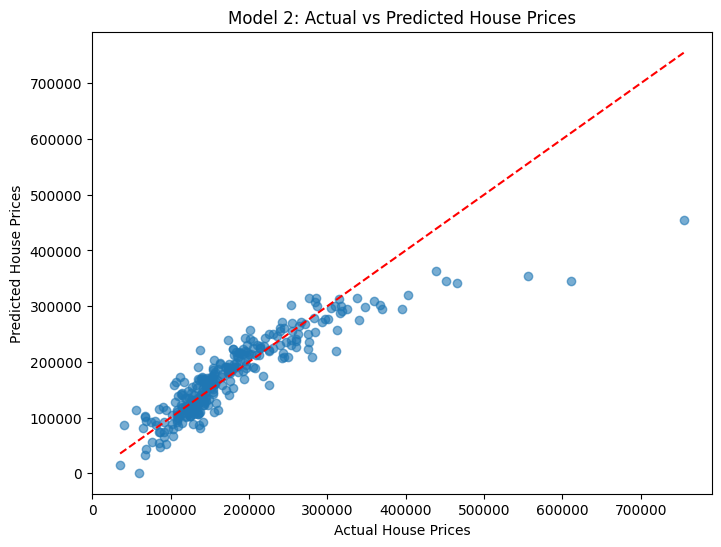

In [27]:
plt.figure(figsize=(8, 6))

plt.scatter(y2_test, y2_pred, alpha=0.6)

plt.xlabel("Actual House Prices")
plt.ylabel("Predicted House Prices")

plt.title("Model 2: Actual vs Predicted House Prices")

plt.plot(
    [y2_test.min(), y2_test.max()],
    [y2_test.min(), y2_test.max()],
    'r--'
)

plt.show()

In [28]:
comparison_results = pd.DataFrame({
    'Metric': ['R2 Score', 'MAE', 'MSE'],
    'Model 1 (5 Features)': [r2, mae, mse],
    'Model 2 (7 Features)': [r2_2, mae_2, mse_2]
})

print(comparison_results)

     Metric  Model 1 (5 Features)  Model 2 (7 Features)
0  R2 Score          7.718564e-01          7.954057e-01
1       MAE          2.781454e+04          2.515594e+04
2       MSE          1.749936e+09          1.569305e+09


In [29]:
new_house = pd.DataFrame({
    'OverallQual': [7],
    'GrLivArea': [2000],
    'GarageCars': [2],
    'TotalBsmtSF': [1000],
    'FullBath': [2],
    'YearBuilt': [2005],
    'YearRemodAdd': [2010]
})

final_prediction = model2.predict(new_house)

print("FINAL HOUSE PRICE PREDICTION")
print("----------------------------")
print("Predicted Price: $", round(final_prediction[0], 2))

FINAL HOUSE PRICE PREDICTION
----------------------------
Predicted Price: $ 238747.09


In [30]:
import joblib

joblib.dump(model2, 'house_price_model.pkl')

print("Model saved successfully!")

Model saved successfully!


In [ ]:
from google.colab import files

files.download('house_price_model.pkl')